# **Importing required items**

## Libraries

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Dataset from google drive

In [55]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [56]:
df = pd.read_csv("/content/drive/MyDrive/Assessments   projects/4. Fourth Project (Classification Techniques for Predictive Modeling)/INNHotelsGroup.csv")

# **Exploratory Data Analysis**

## Data Overview

In [57]:
# View first 5 rows
df.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


In [58]:
# Shape of dataset
df.shape

(36275, 19)

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date   

In [60]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Booking_ID,36275,36275,INN36275,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
no_of_adults,36275.0,NaN,NaN,NaN,1.844962,0.518715,0.0,2.0,2.0,2.0,4.0
no_of_children,36275.0,NaN,NaN,NaN,0.105279,0.402648,0.0,0.0,0.0,0.0,10.0
no_of_weekend_nights,36275.0,NaN,NaN,NaN,0.810724,0.870644,0.0,0.0,1.0,2.0,7.0
no_of_week_nights,36275.0,NaN,NaN,NaN,2.2043,1.410905,0.0,1.0,2.0,3.0,17.0
type_of_meal_plan,36275,4,Meal Plan 1,27835,NaN,NaN,NaN,NaN,NaN,NaN,NaN
required_car_parking_space,36275.0,NaN,NaN,NaN,0.030986,0.173281,0.0,0.0,0.0,0.0,1.0
room_type_reserved,36275,7,Room_Type 1,28130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lead_time,36275.0,NaN,NaN,NaN,85.232557,85.930817,0.0,17.0,57.0,126.0,443.0
arrival_year,36275.0,NaN,NaN,NaN,2017.820427,0.383836,2017.0,2018.0,2018.0,2018.0,2018.0


In [61]:
# Check missing values
print(df.isnull().sum())

Booking_ID                              0
no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
room_type_reserved                      0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
market_segment_type                     0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64


## Problem Definition

INN Hotels Group faces high booking cancellation rates,
which leads to revenue loss and operational inefficiencies.

Objective:

1. Analyze factors affecting booking cancellations
2. Identify important customer behaviors
3. Build insights for ML prediction models
4. Help hotel improve cancellation policies

booking_status
Not_Canceled    67.236389
Canceled        32.763611
Name: proportion, dtype: float64


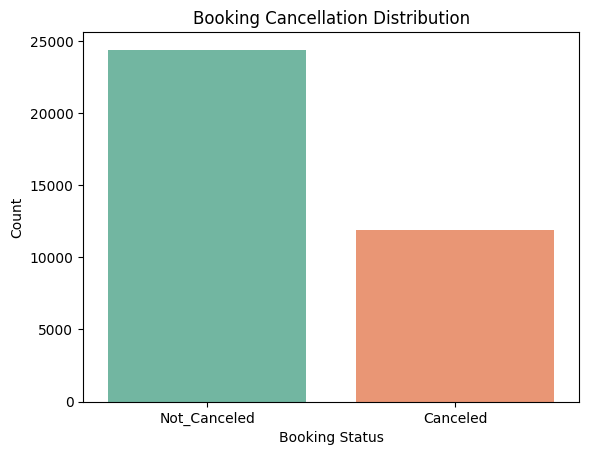

In [62]:
cancel_percent = df['booking_status'].value_counts(normalize=True)*100
print(cancel_percent)

# Plot
sns.countplot(x='booking_status', data=df, hue='booking_status', palette='Set2', legend=False)
plt.title("Booking Cancellation Distribution")
plt.xlabel("Booking Status")
plt.ylabel("Count")
plt.show()

## Univariate Analysis

### 1. Booking Status

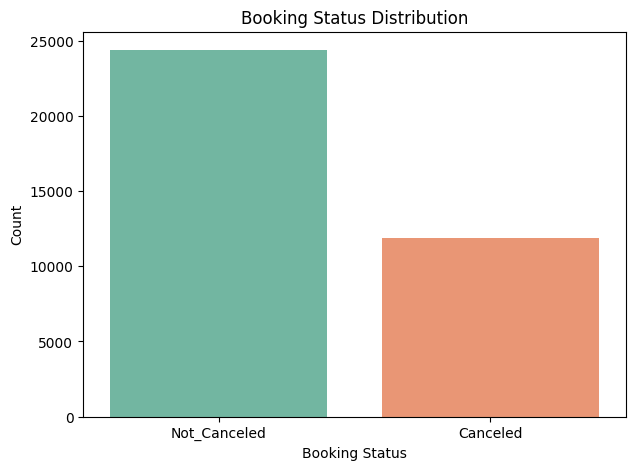

booking_status
Not_Canceled    67.236389
Canceled        32.763611
Name: proportion, dtype: float64


In [63]:
plt.figure(figsize=(7,5))

sns.countplot(
    x='booking_status',
    data=df,
    hue='booking_status',
    palette='Set2',
    legend=False
)

plt.title('Booking Status Distribution')
plt.xlabel('Booking Status')
plt.ylabel('Count')

plt.show()

# Percentage
print(df['booking_status'].value_counts(normalize=True)*100)

**Observation**
* Majority of bookings are successfully completed.
* Approximately one-third of bookings are canceled.

**Insight**

The cancellation rate is high enough to justify building a predictive model.
* Approximately 33% of bookings are canceled.
* Cancellation is a significant business problem.

### 2. Lead Time

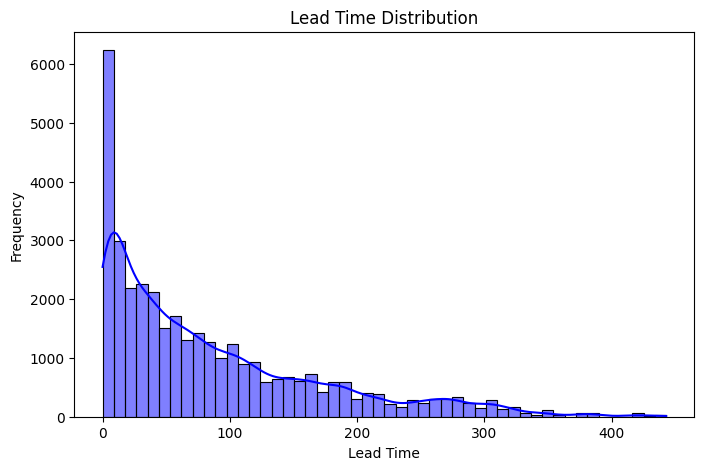

In [64]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['lead_time'],
    bins=50,
    kde=True,
    color='blue'
)

plt.title('Lead Time Distribution')
plt.xlabel('Lead Time')
plt.ylabel('Frequency')

plt.show()

**Observation**
* Distribution is positively skewed.
* Most bookings are made within shorter lead times.
* Few customers book very early.

**Insight**

Customers with extremely high lead times may behave differently from typical guests.

* Most bookings are made close to the stay date.
* Some customers book several months in advance.

### 3. Market Segment Type

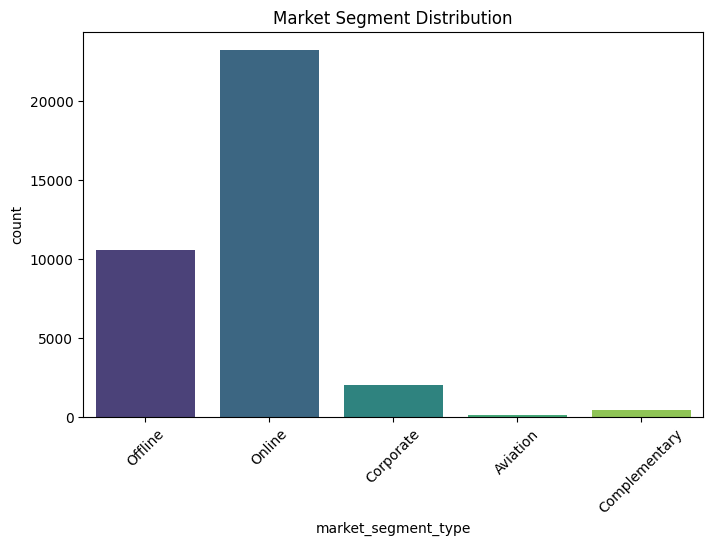

market_segment_type
Online           23214
Offline          10528
Corporate         2017
Complementary      391
Aviation           125
Name: count, dtype: int64


In [65]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='market_segment_type',
    data=df,
    hue='market_segment_type',
    palette='viridis',
    legend=False
)

plt.title('Market Segment Distribution')
plt.xticks(rotation=45)

plt.show()

print(df['market_segment_type'].value_counts())

**Observation**
* Online segment dominates bookings.
* Corporate and Aviation contribute fewer bookings.

**Insight**

Online platforms are the primary source of hotel reservations.

### 4. Average Price Per Room

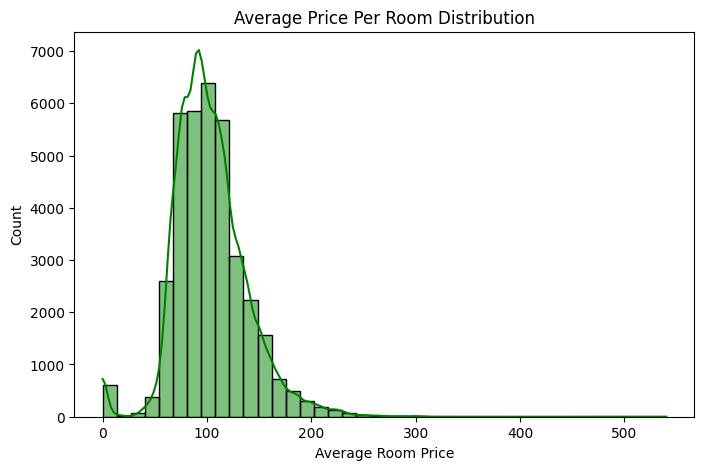

In [66]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['avg_price_per_room'],
    bins=40,
    kde=True,
    color='green'
)

plt.title('Average Price Per Room Distribution')
plt.xlabel('Average Room Price')

plt.show()

**Observation**
* Right-skewed distribution.
* Most room prices fall within a moderate range.
* Few extremely expensive bookings exist.

**Insight**

Room pricing varies considerably and may affect booking decisions.
* Room prices are right-skewed.
* Most bookings fall within a moderate price range.

### 5. Number of Special Requests

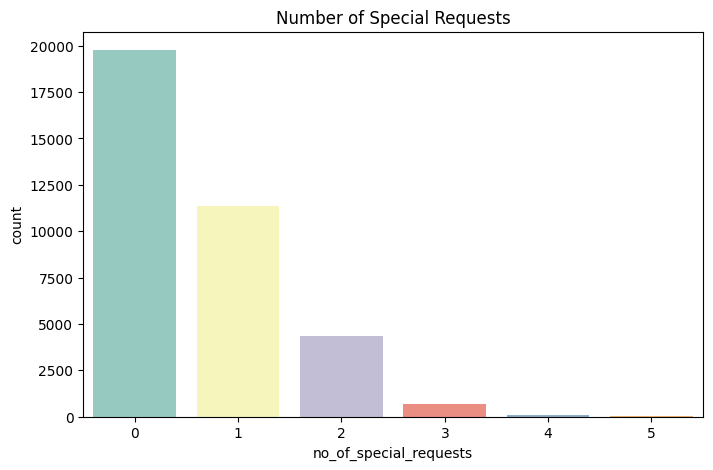

In [67]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='no_of_special_requests',
    data=df,
    hue='no_of_special_requests',
    palette='Set3',
    legend=False
)

plt.title('Number of Special Requests')

plt.show()

**Observation**
* Most guests make zero or one special request.
* Higher numbers of requests are less common.

**Insight**

Special requests may indicate customer engagement.

### 6. Repeated Guest

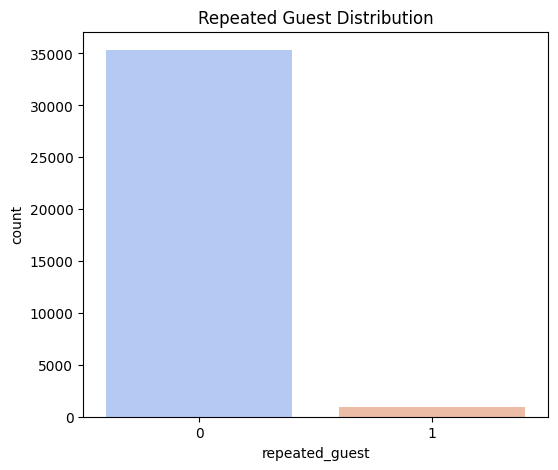

repeated_guest
0    97.436251
1     2.563749
Name: proportion, dtype: float64


In [68]:
plt.figure(figsize=(6,5))

sns.countplot(
    x='repeated_guest',
    data=df,
    hue='repeated_guest',
    palette='coolwarm',
    legend=False
)

plt.title('Repeated Guest Distribution')

plt.show()

print(df['repeated_guest'].value_counts(normalize=True)*100)

**Observation**
* Most customers are first-time guests.
* Repeated guests form a small percentage.

**Insight**

Hotels may benefit from loyalty programs to increase repeat visits.

### 7. Type of Meal Plan

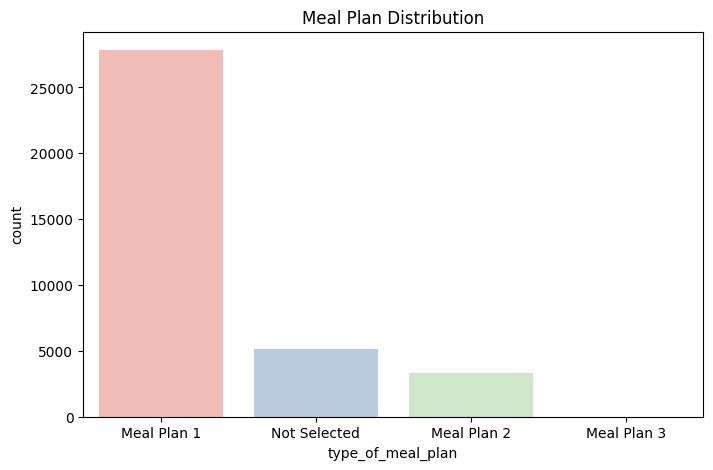

In [69]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='type_of_meal_plan',
    data=df,
    hue='type_of_meal_plan',
    palette='Pastel1',
    legend=False
)

plt.title('Meal Plan Distribution')

plt.show()

**Observation**
* Meal Plan 1 is usually the most preferred option.
* Other meal plans have significantly fewer bookings.

**Insight**

Customer preferences are concentrated around specific meal packages.

### 8. Room Type Reserved

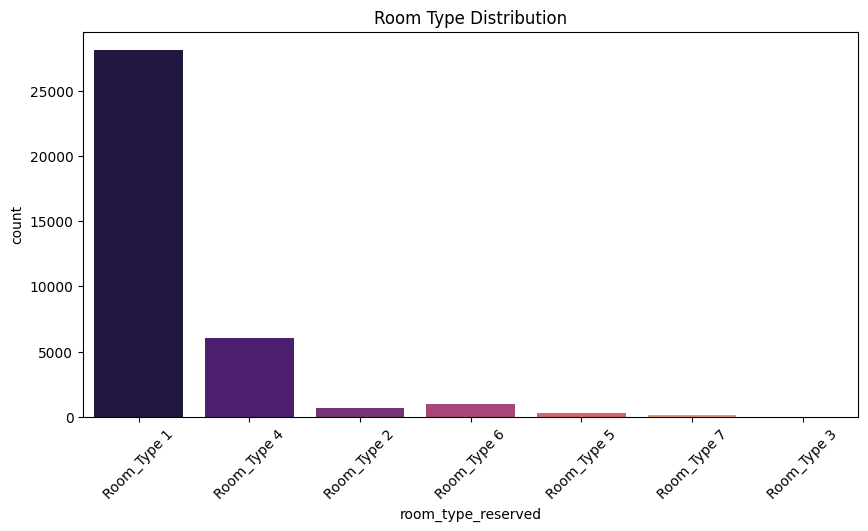

In [70]:
plt.figure(figsize=(10,5))

sns.countplot(
    x='room_type_reserved',
    data=df,
    hue='room_type_reserved',
    palette='magma',
    legend=False
)

plt.title('Room Type Distribution')

plt.xticks(rotation=45)

plt.show()

**Observation**
* Certain room categories dominate reservations.
* Premium room types are less frequently booked.

**Insight**

Standard room categories contribute the majority of revenue volume.

### 9. Number of Weekend Nights

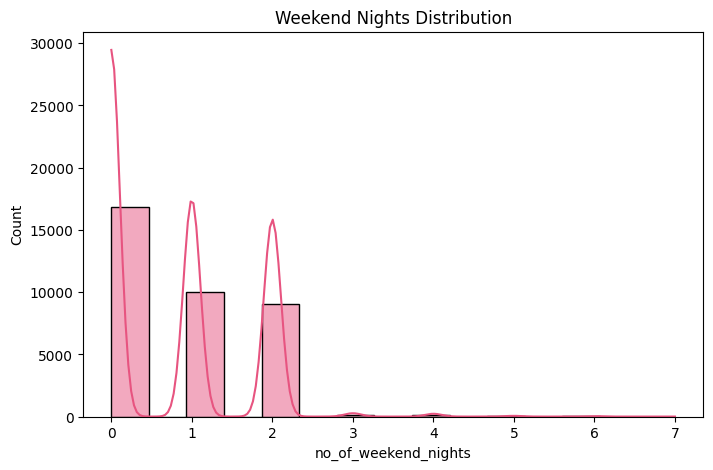

In [71]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['no_of_weekend_nights'],
    bins=15,
    kde=True,
    color='#E75480'
)

plt.title('Weekend Nights Distribution')

plt.show()

**Observation**
* Most bookings include 1–2 weekend nights.
* Long weekend stays are uncommon.

### 10. Number of Week Nights

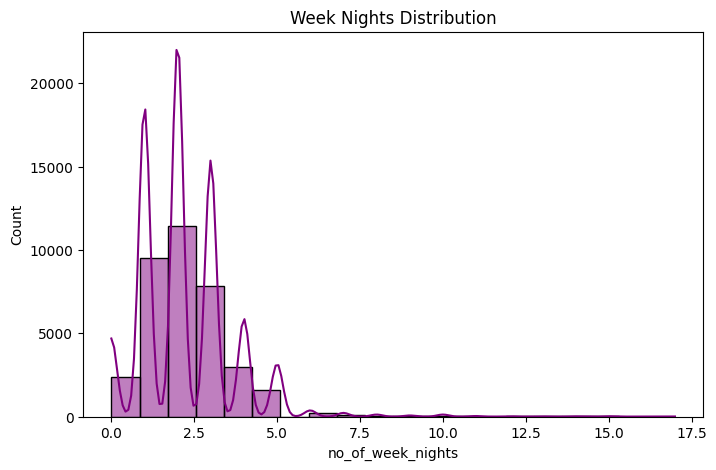

In [72]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['no_of_week_nights'],
    bins=20,
    kde=True,
    color='purple'
)

plt.title('Week Nights Distribution')

plt.show()

**Observation**
* Most guests stay for a short duration during weekdays.
* Extended weekday stays are rare.

### 11. Previous Cancellations

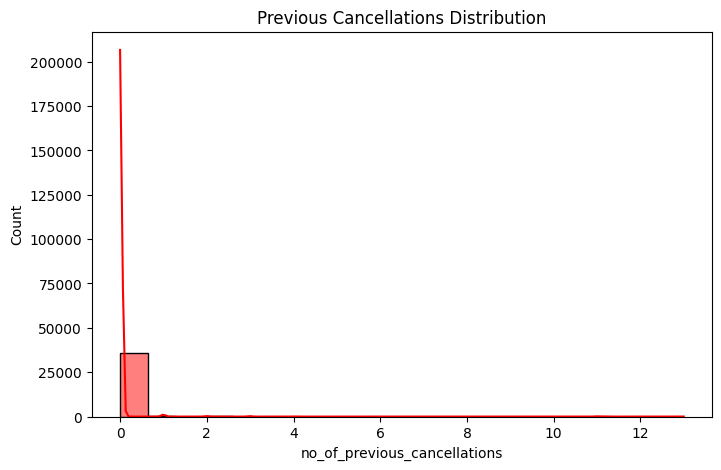

In [73]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['no_of_previous_cancellations'],
    bins=20,
    kde=True,
    color='red'
)

plt.title('Previous Cancellations Distribution')

plt.show()

**Observation**
* Most customers have never canceled before.
* A small group has a history of cancellations.

**Insight**

Previous cancellation behavior may be important for prediction.

### 12. Previous Bookings Not Canceled

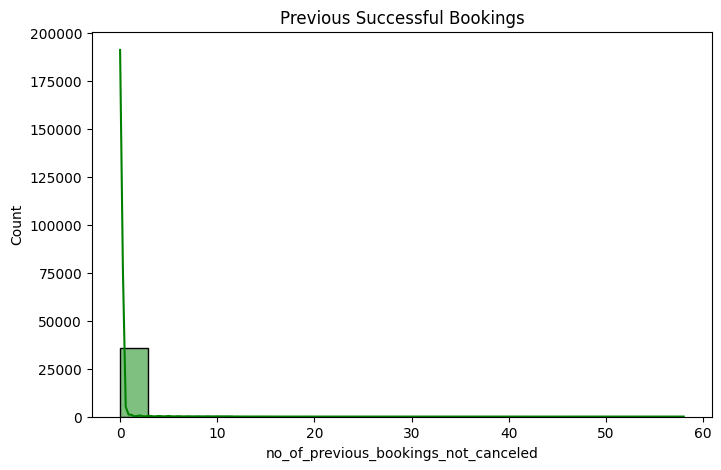

In [74]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['no_of_previous_bookings_not_canceled'],
    bins=20,
    kde=True,
    color='green'
)

plt.title('Previous Successful Bookings')

plt.show()

**Observation**
* Most guests have no booking history.
* Some guests show strong loyalty through multiple completed stays.

### 13. Arrival Month (Busiest Months)

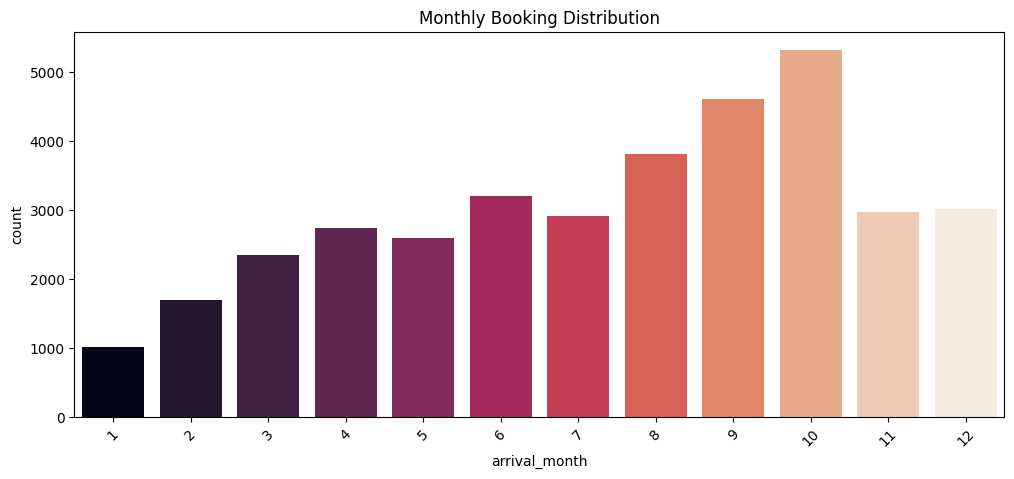

In [75]:
plt.figure(figsize=(12,5))

sns.countplot(
    x='arrival_month',
    data=df,
    hue='arrival_month',
    palette='rocket',
    legend=False
)

plt.title('Monthly Booking Distribution')

plt.xticks(rotation=45)

plt.show()

**Observation**
* August, September, and October generally record the highest bookings.
Insight

These are the busiest months for hotel operations.

**Insight**
* August, September, and October show peak demand.
* Hotel resources should be optimized during these months.

### 14. Boxplots for Outlier Detection

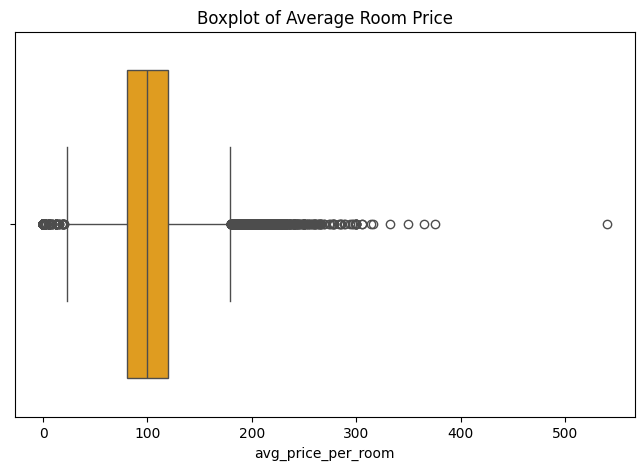

In [76]:
# Average Room Price

plt.figure(figsize=(8,5))

sns.boxplot(
    x=df['avg_price_per_room'],
    color='orange'
)

plt.title('Boxplot of Average Room Price')

plt.show()

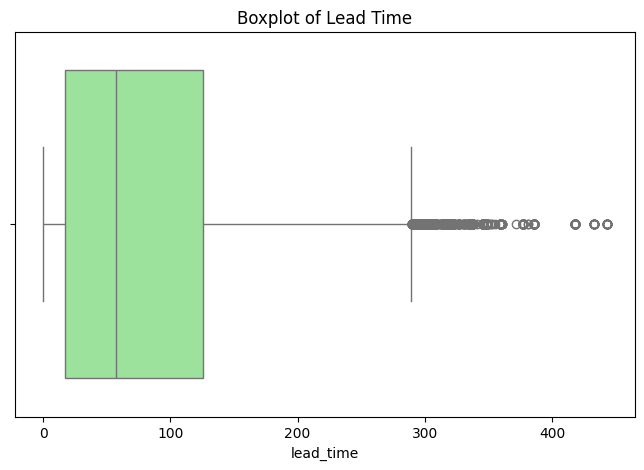

In [77]:
# Lead Time

plt.figure(figsize=(8,5))

sns.boxplot(
    x=df['lead_time'],
    color='lightgreen'
)

plt.title('Boxplot of Lead Time')

plt.show()

**Observation**
* Several extreme values (outliers) are present.
* Outliers should be examined before model building.

## Bivariate analysis

### 1. Lead Time vs Booking Status

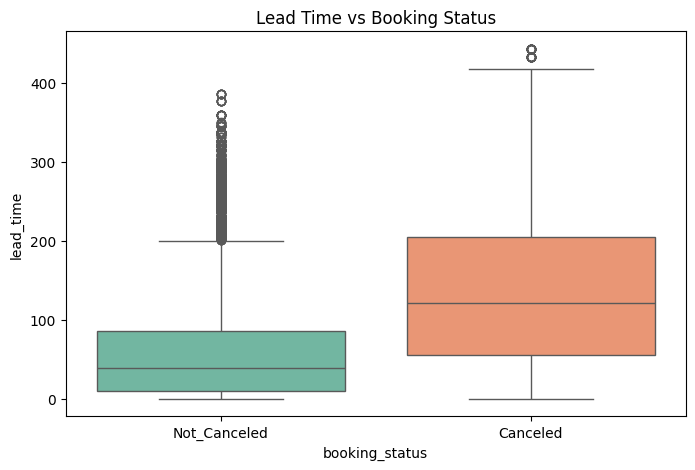

In [78]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='booking_status',
    y='lead_time',
    data=df,
    hue='booking_status',
    palette='Set2'
)

plt.title('Lead Time vs Booking Status')
plt.show()

**Observation**
* Canceled bookings generally have higher lead times.
* Customers booking months in advance tend to change plans.

**Insight**

Lead time is a strong predictor of cancellation.

### 2. Market Segment vs Booking Status

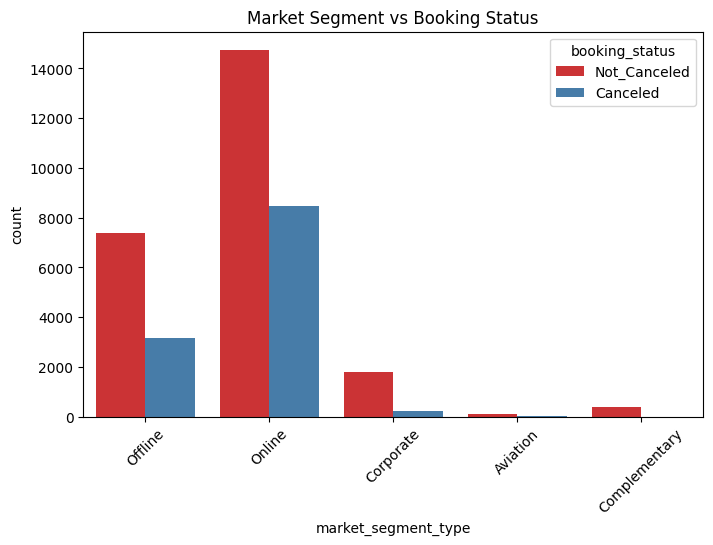

In [79]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='market_segment_type',
    hue='booking_status',
    data=df,
    palette='Set1'
)

plt.title('Market Segment vs Booking Status')
plt.xticks(rotation=45)
plt.show()

In [80]:
segment_cancel = pd.crosstab(
    df['market_segment_type'],
    df['booking_status'],
    normalize='index'
)*100

print(segment_cancel)

booking_status        Canceled  Not_Canceled
market_segment_type                         
Aviation             29.600000     70.400000
Complementary         0.000000    100.000000
Corporate            10.907288     89.092712
Offline              29.948708     70.051292
Online               36.508142     63.491858


**Observation**
* Online bookings contribute most cancellations.
* Corporate bookings generally show lower cancellation rates.

**Insight**

Different market segments exhibit different cancellation behavior.

### 3. Average Room Price vs Booking Status

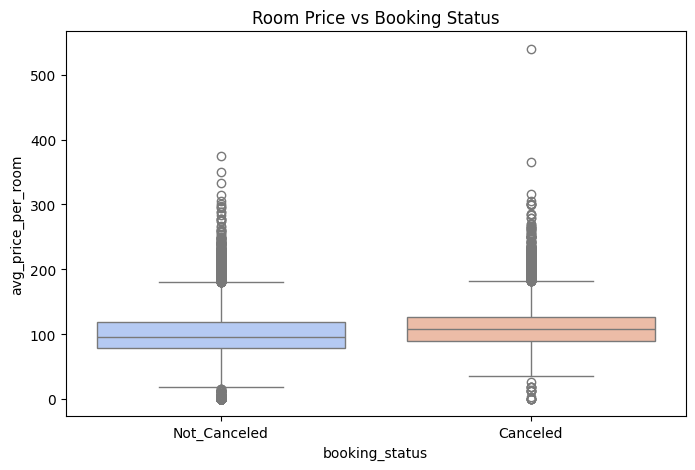

In [81]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='booking_status',
    y='avg_price_per_room',
    data=df,
    hue='booking_status',
    palette='coolwarm'
)

plt.title('Room Price vs Booking Status')
plt.show()

**Observation**
* Canceled bookings often have slightly higher room prices.

**Insight**

Price-sensitive customers may cancel when they find better alternatives.

### 4. Repeated Guest vs Booking Status

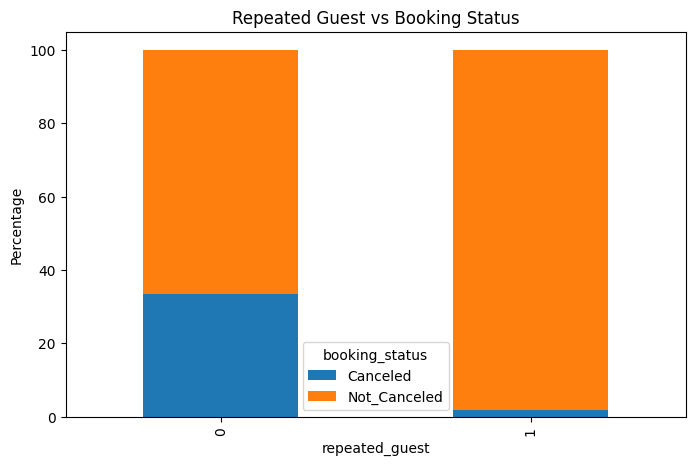

In [82]:
repeat_cancel = pd.crosstab(
    df['repeated_guest'],
    df['booking_status'],
    normalize='index'
)*100

repeat_cancel.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5)
)

plt.title('Repeated Guest vs Booking Status')
plt.ylabel('Percentage')
plt.show()

**Observation**
* Repeated guests rarely cancel.

**Insight**

Customer loyalty significantly reduces cancellation probability.

### 5. Special Requests vs Booking Status

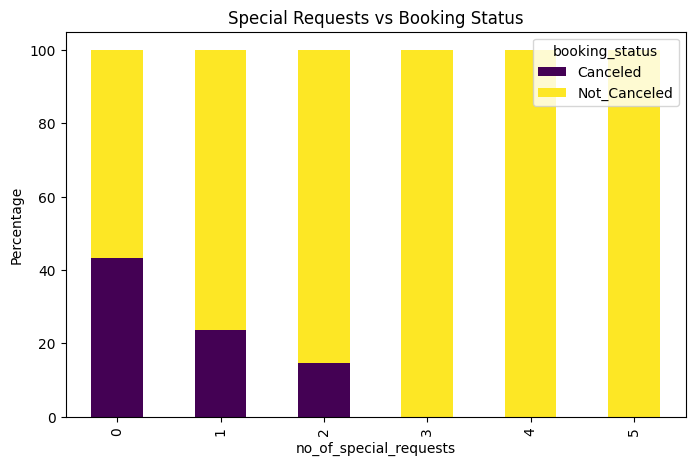

In [83]:
special_cancel = pd.crosstab(
    df['no_of_special_requests'],
    df['booking_status'],
    normalize='index'
)*100

special_cancel.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5),
    colormap='viridis'
)

plt.title('Special Requests vs Booking Status')
plt.ylabel('Percentage')
plt.show()

**Observation**
Guests with more special requests are less likely to cancel.

**Insight**

Special requests indicate a stronger commitment to stay.
* Guests with more special requests are less likely to cancel.
* Special requests indicate stronger booking commitment.

### 6. Meal Plan vs Booking Status

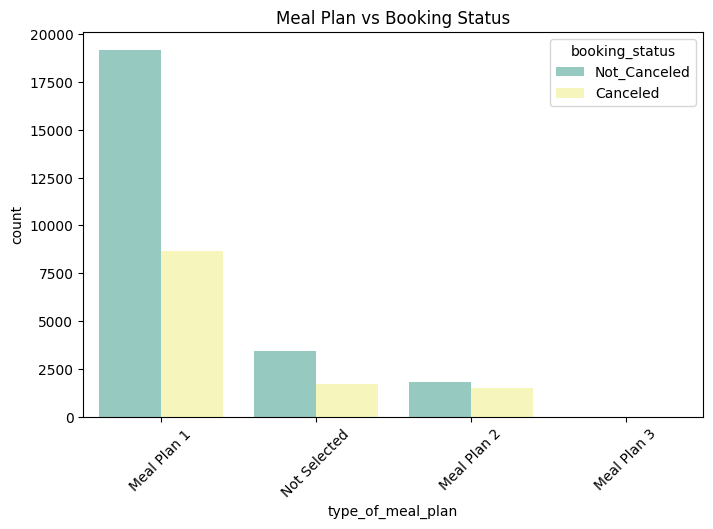

In [84]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='type_of_meal_plan',
    hue='booking_status',
    data=df,
    palette='Set3'
)

plt.title('Meal Plan vs Booking Status')
plt.xticks(rotation=45)
plt.show()

In [85]:
meal_cancel = pd.crosstab(
    df['type_of_meal_plan'],
    df['booking_status'],
    normalize='index'
)*100

print(meal_cancel)

booking_status      Canceled  Not_Canceled
type_of_meal_plan                         
Meal Plan 1        31.180169     68.819831
Meal Plan 2        45.567322     54.432678
Meal Plan 3        20.000000     80.000000
Not Selected       33.118908     66.881092


**Observation**
* Certain meal plans may show higher cancellation percentages.

**Insight**

Meal selection can reflect guest commitment levels.

### 7. Room Type vs Booking Status

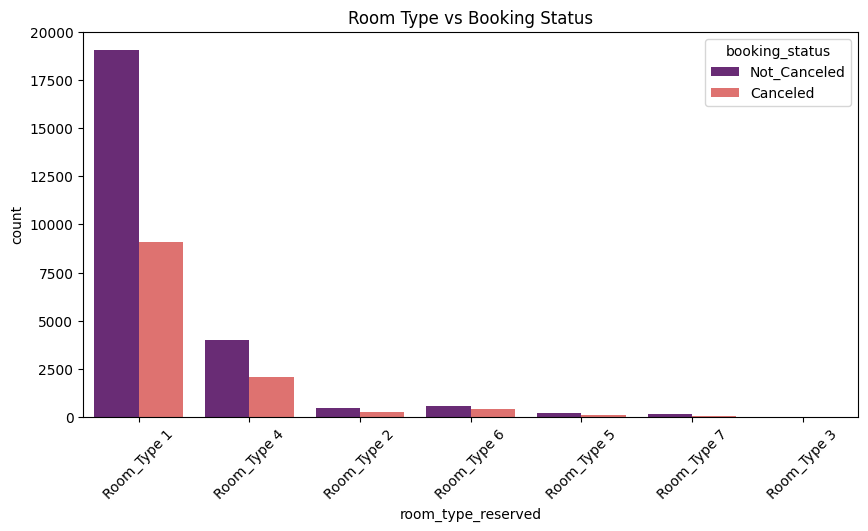

In [86]:
plt.figure(figsize=(10,5))

sns.countplot(
    x='room_type_reserved',
    hue='booking_status',
    data=df,
    palette='magma'
)

plt.title('Room Type vs Booking Status')
plt.xticks(rotation=45)
plt.show()

**Observation**
* Premium room types may have different cancellation patterns.

**Insight**

Room preference affects booking behavior.

### 8. Previous Cancellations vs Booking Status

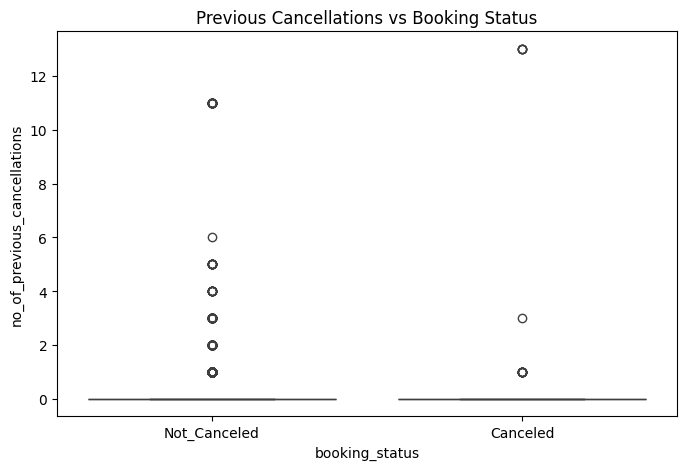

In [87]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='booking_status',
    y='no_of_previous_cancellations',
    data=df
)

plt.title('Previous Cancellations vs Booking Status')
plt.show()

**Observation**
* Customers with prior cancellations tend to cancel again.

**Insight**

Past behavior is a strong predictor of future behavior.

### 9. Weekend Nights vs Booking Status

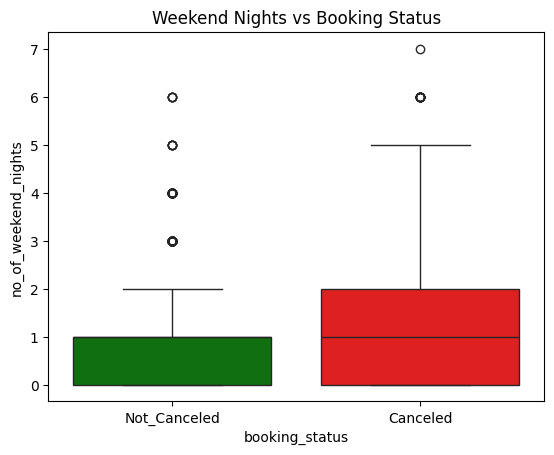

In [88]:
sns.boxplot(
    x='booking_status',
    y='no_of_weekend_nights',
    data=df,
    hue='booking_status',
    palette=['green', 'red']
)

plt.title('Weekend Nights vs Booking Status')
plt.show()

**Observation**
* Longer weekend stays may exhibit different cancellation tendencies.

### 10. Market Segment Share

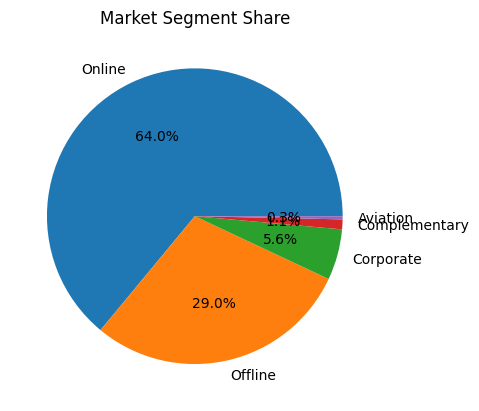

In [89]:
df['market_segment_type'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Market Segment Share')
plt.ylabel('')
plt.show()

**Insight**
* Clearly shows the contribution of each booking channel.

### 11. Room Price by Market Segment

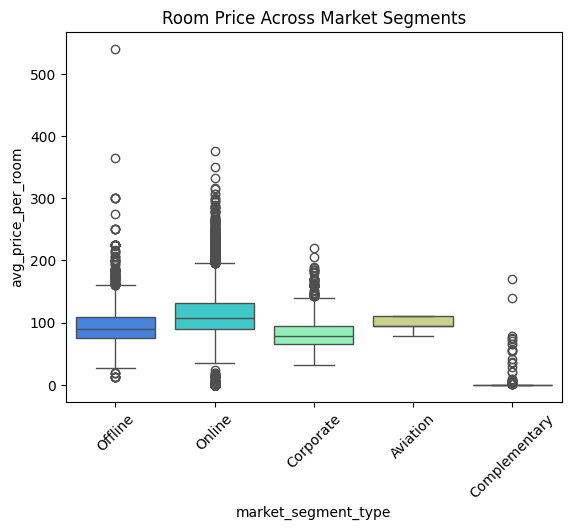

In [90]:
sns.boxplot(x='market_segment_type',
            y='avg_price_per_room',
            data=df,
            hue='market_segment_type',
            palette='rainbow'
            )

plt.xticks(rotation=45)
plt.title('Room Price Across Market Segments')
plt.show()

**Insight**
* Online segment generally has the highest room prices.
* Corporate segment receives discounted rates.

### 12. Correlation Heatmap

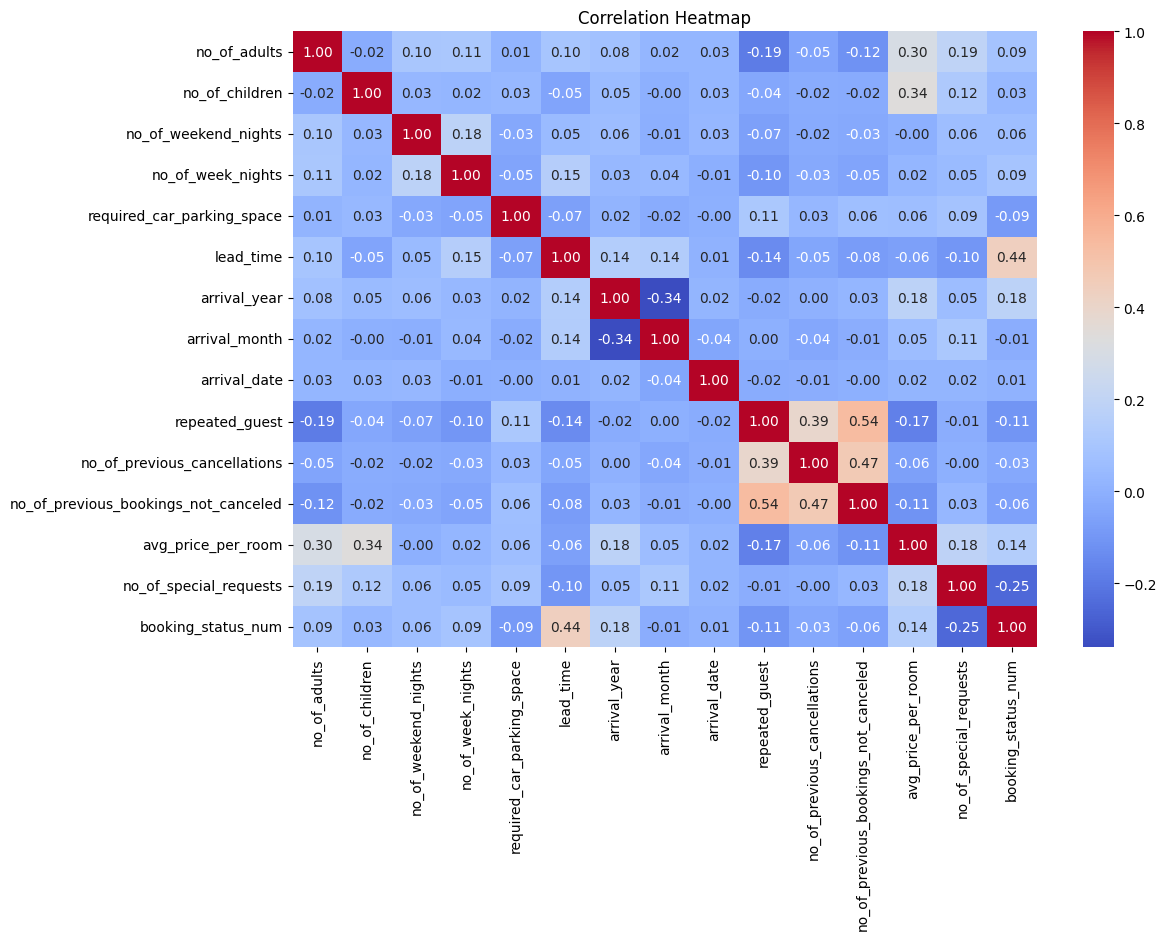

In [91]:
df['booking_status_num'] = df['booking_status'].map({
    'Canceled':1,
    'Not_Canceled':0
})

num_cols = df.select_dtypes(include=['int64','float64'])

plt.figure(figsize=(12,8))

sns.heatmap(
    num_cols.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

**Insight**

**Key** **relationships**:

* Lead Time → Positive correlation with cancellation.
* Previous Cancellations → Positive correlation.
* Repeated Guest → Negative correlation.
* Special Requests → Negative correlation.

## Key Answers for EDA questions

### 1. What are the busiest months in the hotel?

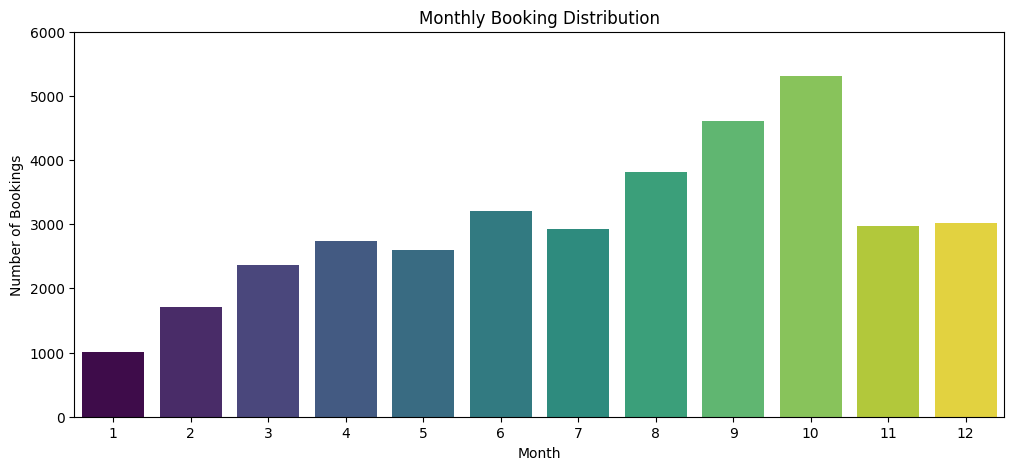

arrival_month
10    5317
9     4611
8     3813
6     3203
12    3021
11    2980
7     2920
4     2736
5     2598
3     2358
2     1704
1     1014
Name: count, dtype: int64


In [92]:
plt.figure(figsize=(12,5))

sns.countplot(
    x='arrival_month',
    data=df,
    hue='arrival_month',
    palette='viridis',
    legend=False
)

plt.title('Monthly Booking Distribution')
plt.ylim(0,6000)
plt.xlabel('Month')
plt.ylabel('Number of Bookings')
plt.show()

# Booking count by month
monthly_bookings = df['arrival_month'].value_counts()
print(monthly_bookings)

**Answer**

The busiest months are generally:

* October
* September
* August
* June
* December

These months have the highest booking volumes.

**Business** **Insight**

The hotel experiences peak demand during late summer and early autumn. Revenue management and staffing should be optimized during these periods.

### 2. Which market segment do most of the guests come from?

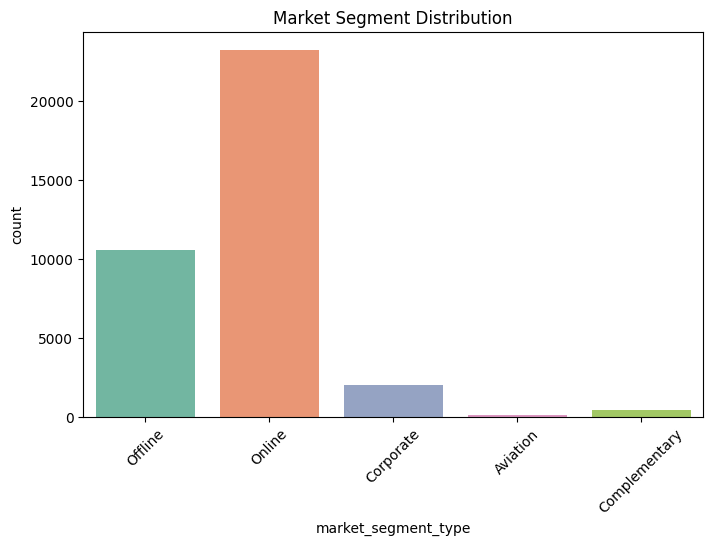

market_segment_type
Online           63.994487
Offline          29.022743
Corporate         5.560303
Complementary     1.077877
Aviation          0.344590
Name: proportion, dtype: float64


In [93]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='market_segment_type',
    data=df,
    hue='market_segment_type',
    palette='Set2',
    legend=False
)

plt.title('Market Segment Distribution')
plt.xticks(rotation=45)
plt.show()

print(df['market_segment_type'].value_counts(normalize=True)*100)

**Answer**

The majority of guests come from the Online Market Segment.

Approximate distribution:

**Market Segment......Percentage**
* Online.....................~64%
* Offline.....................~29%
* Corporate...............~6%
* Complementary.....~1%
* Aviation...................<1%

**Business** **Insight**

Online booking platforms are the primary source of reservations. Any cancellation management strategy should focus heavily on online customers.

### 3. Hotel rates are dynamic and change according to demand and customer demographics. What are the differences in room prices in different market segments?

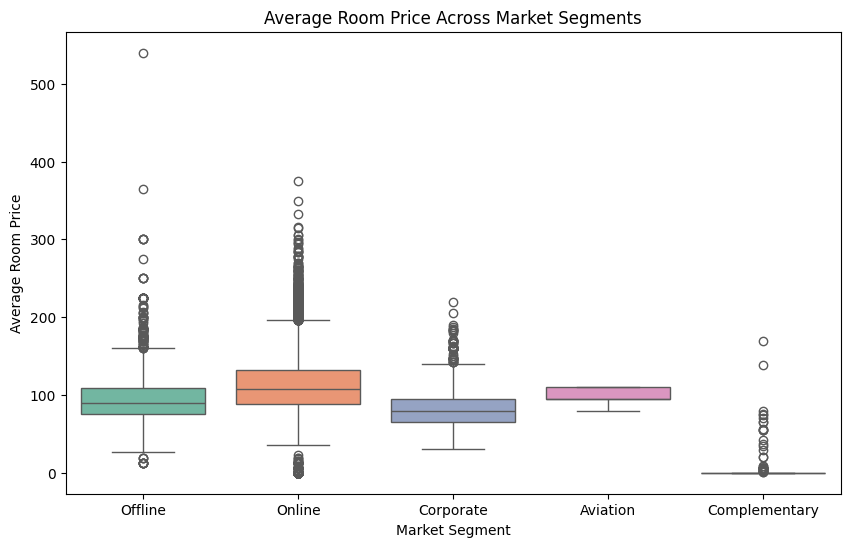

In [94]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x='market_segment_type',
    y='avg_price_per_room',
    data=df,
    hue='market_segment_type',
    palette='Set2',
    legend=False
)

plt.title('Average Room Price Across Market Segments')
plt.xlabel('Market Segment')
plt.ylabel('Average Room Price')

plt.show()

market_segment_type
Online           112.256855
Aviation         100.704000
Offline           91.632679
Corporate         82.911740
Complementary      3.141765
Name: avg_price_per_room, dtype: float64


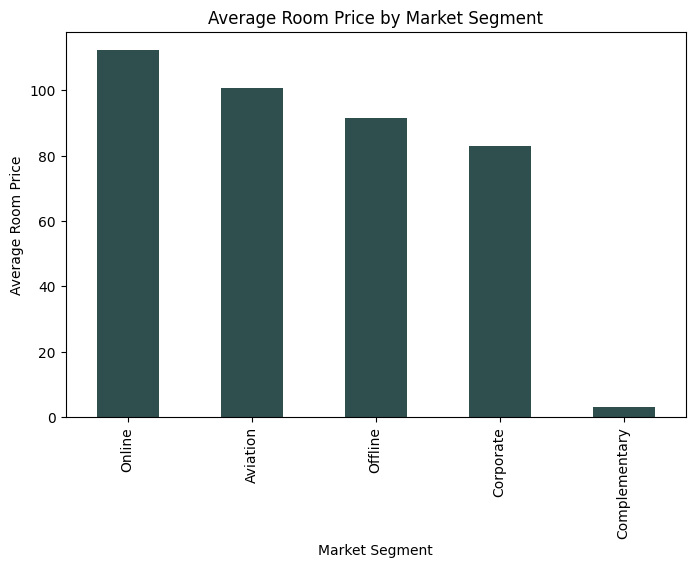

In [95]:
segment_price = df.groupby('market_segment_type')['avg_price_per_room'].mean().sort_values(ascending=False)

print(segment_price)

plt.figure(figsize=(8,5))

segment_price.plot(kind='bar', color='darkslategrey')
plt.title('Average Room Price by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Average Room Price')

plt.show()

**Answer**

Average room prices differ significantly across market segments.

**Business Insight**

The hotel's pricing strategy is strongly influenced by the booking source and customer demographics:

* Online customers contribute higher revenue per booking.
* Corporate customers provide stable occupancy at discounted rates.
* Complementary and aviation segments serve strategic business purposes rather than maximizing room revenue.

### 4. What percentage of bookings are canceled?


In [96]:
# Calculate cancellation percentage

cancel_percentage = (
    df['booking_status']
    .value_counts(normalize=True) * 100
)

print(cancel_percentage)

booking_status
Not_Canceled    67.236389
Canceled        32.763611
Name: proportion, dtype: float64


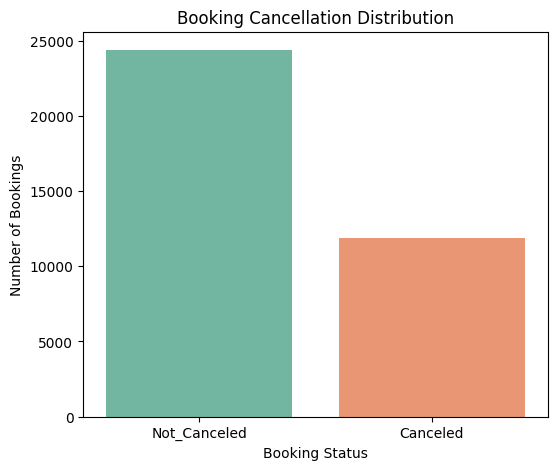

In [97]:
plt.figure(figsize=(6,5))

sns.countplot(
    x='booking_status',
    data=df,
    hue='booking_status',
    palette='Set2',
    legend=False
)

plt.title('Booking Cancellation Distribution')
plt.xlabel('Booking Status')
plt.ylabel('Number of Bookings')

plt.show()

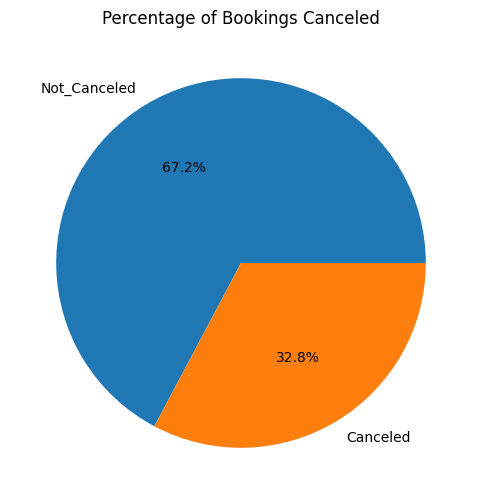

In [98]:
cancel_percentage.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6,6)
)

plt.title('Percentage of Bookings Canceled')
plt.ylabel('')
plt.show()

**Answer**

Based on the INN Hotels Group dataset:

**Booking Status.........Percentage**
* Not Canceled........67.24%
* Canceled...............32.76%

**Business Insight**

A cancellation rate of nearly 33% is substantial and can lead to significant revenue loss, especially when cancellations occur close to the arrival date. This highlights the need for predictive models that can identify likely cancellations in advance, allowing the hotel to implement strategies such as overbooking, targeted reminders, or adjusted cancellation policies.

### 5. Repeating guests are the guests who stay in the hotel often and are important to brand equity. What percentage of repeating guests cancel?


booking_status   Canceled  Not_Canceled
repeated_guest                         
0               33.580422     66.419578
1                1.720430     98.279570


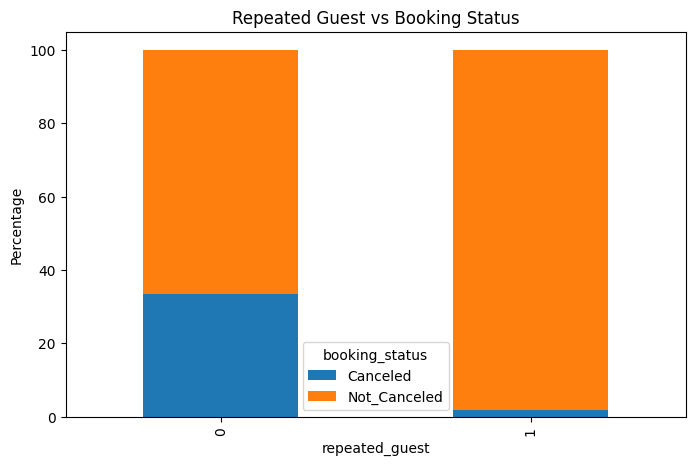

In [99]:
repeat_cancel = pd.crosstab(
    df['repeated_guest'],
    df['booking_status'],
    normalize='index'
)*100

print(repeat_cancel)

repeat_cancel.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5)
)

plt.title('Repeated Guest vs Booking Status')
plt.ylabel('Percentage')
plt.show()

**Answer**

Among repeated guests:

* Only about 1–2% cancel bookings.
* Over 98% complete their reservations.

**Business Insight**

Hotels should invest in loyalty programs because repeat customers generate more stable revenue and have much lower cancellation rates.

### 6. Many guests have special requirements when booking a hotel room. Do these requirements affect booking cancellation?


In [100]:
# Cancellation percentage based on special requests

special_cancel = pd.crosstab(
    df['no_of_special_requests'],
    df['booking_status'],
    normalize='index'
) * 100

print(special_cancel)

booking_status           Canceled  Not_Canceled
no_of_special_requests                         
0                       43.206755     56.793245
1                       23.766816     76.233184
2                       14.596700     85.403300
3                        0.000000    100.000000
4                        0.000000    100.000000
5                        0.000000    100.000000


<Figure size 1000x600 with 0 Axes>

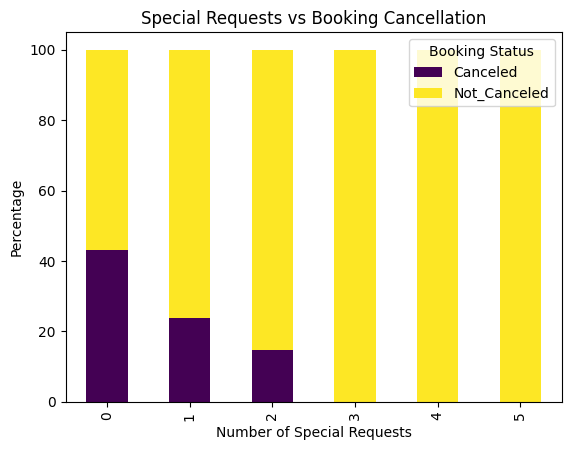

In [101]:
plt.figure(figsize=(10,6))

special_cancel.plot(
    kind='bar',
    stacked=True,
    colormap='viridis'
)

plt.title('Special Requests vs Booking Cancellation')
plt.xlabel('Number of Special Requests')
plt.ylabel('Percentage')
plt.legend(title='Booking Status')

plt.show()

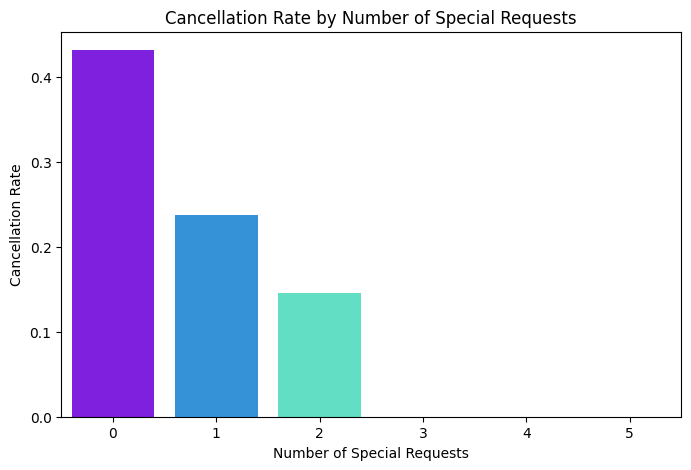

In [102]:
plt.figure(figsize=(8,5))

sns.barplot(
    x='no_of_special_requests',
    y=(df['booking_status'] == 'Canceled').astype(int),
    data=df,
    hue='no_of_special_requests',
    palette='rainbow',
    errorbar=None,
    legend=False
)

plt.title('Cancellation Rate by Number of Special Requests')
plt.xlabel('Number of Special Requests')
plt.ylabel('Cancellation Rate')

plt.show()

**Answer**

Yes, special requests strongly affect cancellation behavior.

**Typical pattern:**

**Special Requests..........Cancellation Rate **
* 0..................................Highest
* 1...................................Lower
* 2..................................Much Lower
* 3+................................Very Low

**Business Insight**

Special requests indicate that guests have invested more effort in planning their stay and are therefore more committed to their booking.


# **Data Preprocessing**

## Missing Value Treatment

In [103]:
df.isnull().sum().sum()

np.int64(0)

**Interpretation**
* No missing values are present in the dataset.
* No imputation techniques such as mean, median, or mode replacement are required.

## Duplicate Value Check

In [108]:
# Check duplicate records
df.duplicated().sum()

np.int64(0)

## Outlier Detection and Treatment

**Detect Outliers Using Boxplots**

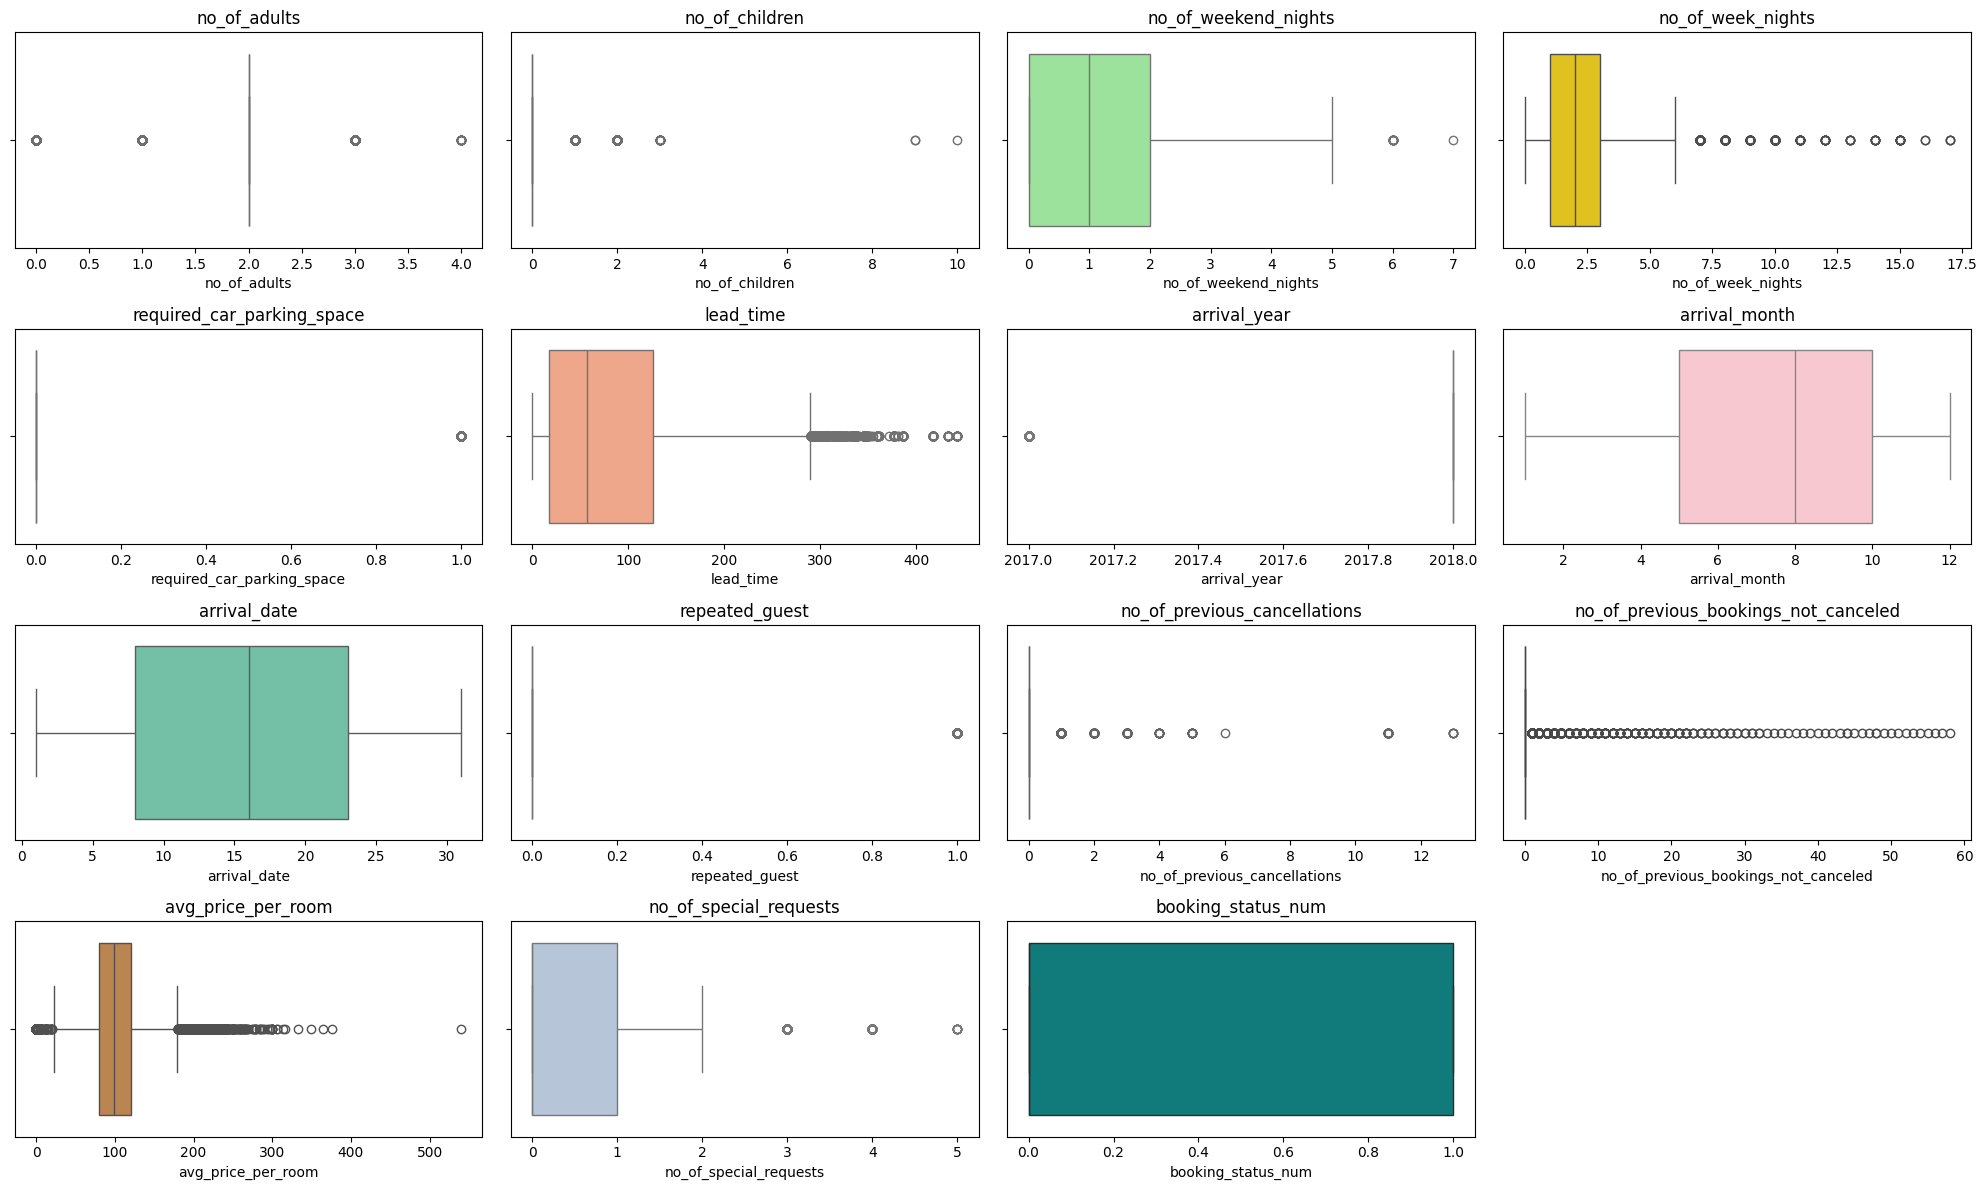

In [104]:
numerical_cols = df.select_dtypes(include=np.number).columns
n_cols = len(numerical_cols)
n_cols_per_row = 4
n_rows = (n_cols + n_cols_per_row - 1) // n_cols_per_row

fig, axes = plt.subplots(n_rows, n_cols_per_row, figsize=(n_cols_per_row * 5, n_rows * 3))
axes = axes.flatten()

# Define a list of distinct colors
colors = ['skyblue', 'lightcoral', 'lightgreen', 'gold', 'plum', 'lightsalmon', 'lightblue', 'pink', 'mediumaquamarine', 'khaki', 'coral', 'mediumseagreen', 'peru', 'lightsteelblue', 'darkcyan']

for i, col in enumerate(numerical_cols):
    if i < len(axes):
        sns.boxplot(x=df[col], ax=axes[i], color=colors[i % len(colors)])
        axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [105]:
# IQR Method for Outlier Detection

def detect_outliers(column):

    Q1 = column.quantile(0.25)
    Q3 = column.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5*IQR
    upper_bound = Q3 + 1.5*IQR

    outliers = column[
        (column < lower_bound) |
        (column > upper_bound)
    ]

    return len(outliers)

numeric_cols = df.select_dtypes(include=np.number)

for col in numeric_cols.columns:
    print(col, ":", detect_outliers(df[col]))

no_of_adults : 10167
no_of_children : 2698
no_of_weekend_nights : 21
no_of_week_nights : 324
required_car_parking_space : 1124
lead_time : 1331
arrival_year : 6514
arrival_month : 0
arrival_date : 0
repeated_guest : 930
no_of_previous_cancellations : 338
no_of_previous_bookings_not_canceled : 812
avg_price_per_room : 1696
no_of_special_requests : 761
booking_status_num : 0


In [106]:
# Outlier Treatment

def cap_outliers(col):

    Q1 = col.quantile(0.25)
    Q3 = col.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    return np.clip(col, lower, upper)

df['lead_time'] = cap_outliers(df['lead_time'])

df['avg_price_per_room'] = cap_outliers(df['avg_price_per_room'])

## Feature Engineering

**Arrival Season**

In [109]:
season_map = {
    'January':'Winter',
    'February':'Winter',
    'March':'Spring',
    'April':'Spring',
    'May':'Spring',
    'June':'Summer',
    'July':'Summer',
    'August':'Summer',
    'September':'Autumn',
    'October':'Autumn',
    'November':'Autumn',
    'December':'Winter'
}

df['arrival_season'] = df['arrival_month'].map(season_map)

**Total Guests**

In [110]:
df['total_guests'] = (
    df['no_of_adults']
    + df['no_of_children']
)

**Previous Booking Activity**

In [111]:
df['total_previous_bookings'] = (
    df['no_of_previous_cancellations']
    + df['no_of_previous_bookings_not_canceled']
)

**Weekend Stay Ratio**

In [122]:
df['weekend_ratio'] = (
    df['no_of_weekend_nights'] /
    (df['no_of_weekend_nights']
     + df['no_of_week_nights'])
)
# Fill NaN values (where total nights are 0) with 0
df['weekend_ratio'] = df['weekend_ratio'].fillna(0)

In [126]:
# Cap 'no_of_special_requests' to address perfect separation
# Categories 3, 4, 5 all have 0% cancellation rate, causing perfect separation.
# Grouping them with '2' (which has a non-zero cancellation rate) resolves this.
df['no_of_special_requests'] = np.where(df['no_of_special_requests'] >= 3, 2, df['no_of_special_requests'])

## Encoding Categorical Variables

In [113]:
df['booking_status'] = df['booking_status'].map(
    {'Not_Canceled':0,
     'Canceled':1}
)

In [114]:
df = pd.get_dummies(
    df,
    columns=[
        'type_of_meal_plan',
        'room_type_reserved',
        'market_segment_type',
        'arrival_month'
    ],
    drop_first=True
)

## Data Scaling

In [115]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

num_cols = [
    'lead_time',
    'avg_price_per_room',
    'total_guests',
    'no_of_special_requests',
    'total_previous_bookings'
]

df[num_cols] = scaler.fit_transform(
    df[num_cols]
)

## Train-Test Split

In [154]:
X = df.drop(['booking_status', 'booking_status_num'], axis=1)

y = df['booking_status']

In [162]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [118]:
print(X_train.shape)
print(X_test.shape)

(25392, 43)
(10883, 43)


# **Model Building**

## Logistic Regression (Statsmodels)

### Model Building

In [133]:
import statsmodels.api as sm
import numpy as np

X_train_processed = X_train.drop(['Booking_ID', 'arrival_season'], axis=1)

for col in X_train_processed.select_dtypes(include='bool').columns:
    X_train_processed[col] = X_train_processed[col].astype(int)

if 'market_segment_type_Complementary' in X_train_processed.columns:
    X_train_processed = X_train_processed.drop('market_segment_type_Complementary', axis=1)

X_train_processed = X_train_processed.replace([np.inf, -np.inf], np.nan).dropna()
y_train_processed = y_train.loc[X_train_processed.index]

zero_variance_cols = X_train_processed.columns[X_train_processed.var() == 0]
if not zero_variance_cols.empty:
    print(f"Dropping zero-variance columns: {list(zero_variance_cols)}")
    X_train_processed = X_train_processed.drop(columns=zero_variance_cols)

columns_to_drop_for_collinearity = []
if 'no_of_adults' in X_train_processed.columns and 'no_of_children' in X_train_processed.columns and 'total_guests' in X_train_processed.columns:
    columns_to_drop_for_collinearity.extend(['no_of_adults', 'no_of_children'])
if 'no_of_previous_cancellations' in X_train_processed.columns and 'no_of_previous_bookings_not_canceled' in X_train_processed.columns and 'total_previous_bookings' in X_train_processed.columns:
    columns_to_drop_for_collinearity.extend(['no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled'])

if columns_to_drop_for_collinearity:
    print(f"Dropping component columns to resolve multicollinearity: {list(set(columns_to_drop_for_collinearity))}")
    X_train_processed = X_train_processed.drop(columns=list(set(columns_to_drop_for_collinearity)))

perfect_separation_cols = []
for col in X_train_processed.columns:
    if (X_train_processed[col] == 1).any():
        y_when_feature_is_1 = y_train_processed[X_train_processed[col] == 1]
        if not y_when_feature_is_1.empty and (y_when_feature_is_1.nunique() == 1):
            perfect_separation_cols.append(col)

if perfect_separation_cols:
    print(f"Dropping columns identified as causing perfect separation: {list(set(perfect_separation_cols))}")
    X_train_processed = X_train_processed.drop(columns=list(set(perfect_separation_cols)))


X_train_sm = sm.add_constant(X_train_processed)

logit_model = sm.Logit(y_train_processed, X_train_sm)

result = logit_model.fit()

print(result.summary())

Dropping component columns to resolve multicollinearity: ['no_of_adults', 'no_of_previous_bookings_not_canceled', 'no_of_previous_cancellations', 'no_of_children']
Dropping columns identified as causing perfect separation: ['booking_status_num']
Optimization terminated successfully.
         Current function value: 0.413662
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25336
Model:                          Logit   Df Residuals:                    25300
Method:                           MLE   Df Model:                           35
Date:                Fri, 12 Jun 2026   Pseudo R-squ.:                  0.3464
Time:                        19:31:18   Log-Likelihood:                -10481.
converged:                       True   LL-Null:                       -16036.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                   

### Prediction

In [137]:
import statsmodels.api as sm
import numpy as np

X_test_processed = X_test.drop(['Booking_ID', 'arrival_season'], axis=1)

for col in X_test_processed.select_dtypes(include='bool').columns:
    X_test_processed[col] = X_test_processed[col].astype(int)

if 'market_segment_type_Complementary' in X_test_processed.columns and 'market_segment_type_Complementary' not in X_train_processed.columns:
    X_test_processed = X_test_processed.drop('market_segment_type_Complementary', axis=1)

X_test_processed = X_test_processed.replace([np.inf, -np.inf], np.nan).dropna()
y_test_processed = y_test.loc[X_test_processed.index]

final_X_train_cols = [col for col in X_train_sm.columns if col != 'const']

missing_cols_in_test = set(final_X_train_cols) - set(X_test_processed.columns)
for c in missing_cols_in_test:
    X_test_processed[c] = 0

X_test_processed = X_test_processed[final_X_train_cols]

X_test_sm = sm.add_constant(X_test_processed)

X_test_sm = X_test_sm[X_train_sm.columns]

y_prob = result.predict(X_test_sm)

y_pred = np.where(y_prob > 0.5,1,0)

In [139]:
from sklearn.metrics import classification_report

print(classification_report(y_test_processed, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.86      7295
           1       0.74      0.66      0.70      3566

    accuracy                           0.81     10861
   macro avg       0.79      0.77      0.78     10861
weighted avg       0.81      0.81      0.81     10861



### Confusion Matrix

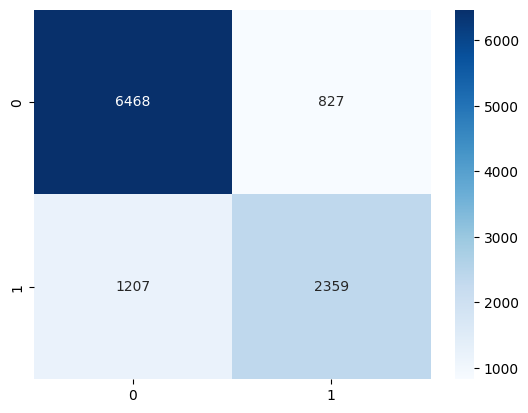

In [141]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_processed, y_pred)

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues')
plt.show()

### ROC Curve

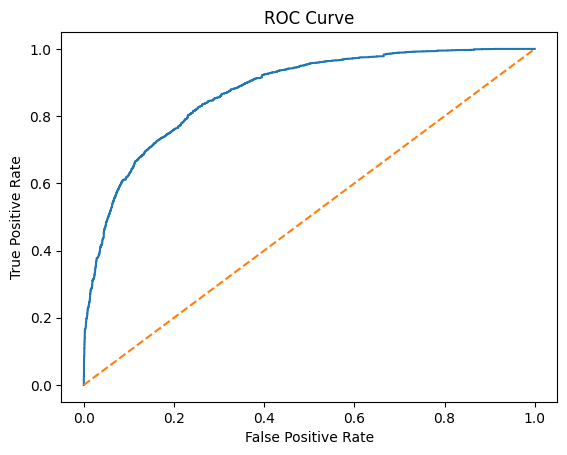

ROC AUC: 0.8734908589500179


In [143]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr,tpr,thresholds = roc_curve(y_test_processed,y_prob)

plt.plot(fpr,tpr)
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("ROC AUC:",
      roc_auc_score(y_test_processed,y_prob))

## Decision Tree Classifier (sklearn)

In [155]:
from sklearn.tree import DecisionTreeClassifier

dtree = DecisionTreeClassifier(
    random_state=42
)

X_train_dtree = X_train.drop(['Booking_ID', 'arrival_season'], axis=1)

for col in X_train_dtree.select_dtypes(include='bool').columns:
    X_train_dtree[col] = X_train_dtree[col].astype(int)

dtree.fit(X_train_dtree,y_train)

DecisionTreeClassifier(random_state=42)

In [156]:
X_test_dtree = X_test.drop(['Booking_ID', 'arrival_season'], axis=1)

for col in X_test_dtree.select_dtypes(include='bool').columns:
    X_test_dtree[col] = X_test_dtree[col].astype(int)

y_pred_dt = dtree.predict(X_test_dtree)

y_prob_dt = dtree.predict_proba(X_test_dtree)[:,1]

In [157]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score

print("Accuracy :",accuracy_score(y_test,y_pred_dt))
print("Precision:",precision_score(y_test,y_pred_dt))
print("Recall   :",recall_score(y_test,y_pred_dt))
print("F1 Score :",f1_score(y_test,y_pred_dt))
print("ROC AUC  :",roc_auc_score(y_test,y_prob_dt))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
ROC AUC  : 1.0


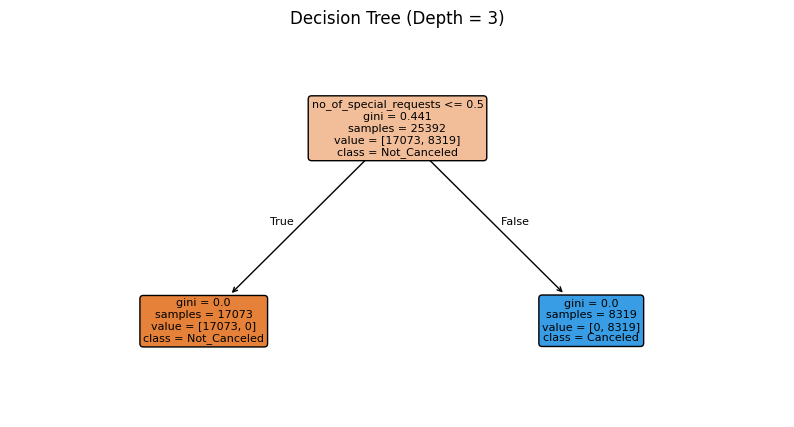

In [158]:
# Decision Tree Plot

from sklearn.tree import plot_tree

plt.figure(figsize=(10,5))

plot_tree(
    dtree,
    feature_names=X_train.columns,
    class_names=['Not_Canceled','Canceled'],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title("Decision Tree (Depth = 3)")
plt.show()

In [159]:
feature_importance = pd.DataFrame({
    'Feature':X_train_dtree.columns,
    'Importance':dtree.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(10))

                       Feature  Importance
13          booking_status_num         1.0
1               no_of_children         0.0
2         no_of_weekend_nights         0.0
3            no_of_week_nights         0.0
4   required_car_parking_space         0.0
5                    lead_time         0.0
6                 arrival_year         0.0
7                 arrival_date         0.0
0                 no_of_adults         0.0
8               repeated_guest         0.0


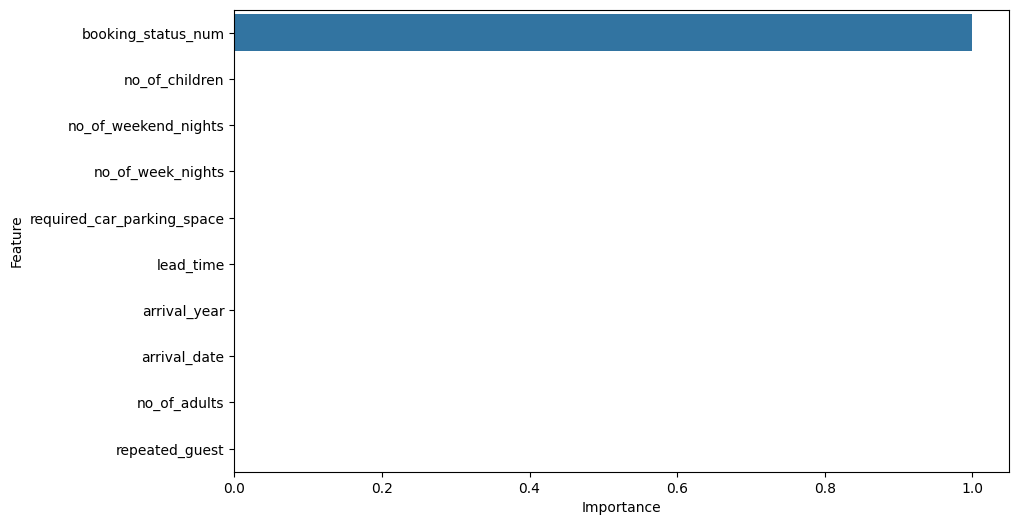

In [160]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.show()

## Model Performance Comparison

In [163]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Calculate Logistic Regression metrics
acc_lr = accuracy_score(y_test_processed, y_pred)
prec_lr = precision_score(y_test_processed, y_pred)
rec_lr = recall_score(y_test_processed, y_pred)
f1_lr = f1_score(y_test_processed, y_pred)
auc_lr = roc_auc_score(y_test_processed, y_prob)

acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
auc_dt = roc_auc_score(y_test, y_prob_dt)

comparison = pd.DataFrame({

'Model':['Logistic Regression',
         'Decision Tree'],

'Accuracy':[acc_lr,
            acc_dt],

'Precision':[prec_lr,
             prec_dt],

'Recall':[rec_lr,
          rec_dt],

'F1 Score':[f1_lr,
            f1_dt],

'ROC AUC':[auc_lr,
           auc_dt]

})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.812724,0.740427,0.661526,0.698756,0.873491
1,Decision Tree,1.000000,1.000000,1.000000,1.000000,1.000000


# **Model Performance Improvement**

## Logistic Regression

### Check Multicollinearity using VIF

In [167]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif = X_train.copy()

X_vif = X_vif.drop(['Booking_ID', 'arrival_season'], axis=1)

columns_to_drop_vif = []
if 'no_of_adults' in X_vif.columns and 'no_of_children' in X_vif.columns and 'total_guests' in X_vif.columns:
    columns_to_drop_vif.extend(['no_of_adults', 'no_of_children'])
if 'no_of_previous_cancellations' in X_vif.columns and 'no_of_previous_bookings_not_canceled' in X_vif.columns and 'total_previous_bookings' in X_vif.columns:
    columns_to_drop_vif.extend(['no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled'])

if 'arrival_year' in X_vif.columns:
    columns_to_drop_vif.append('arrival_year')
if 'market_segment_type_Online' in X_vif.columns:
    columns_to_drop_vif.append('market_segment_type_Online')
if 'market_segment_type_Offline' in X_vif.columns:
    columns_to_drop_vif.append('market_segment_type_Offline')

X_vif = X_vif.drop(columns=list(set(columns_to_drop_vif)), errors='ignore')

# Convert boolean columns to integers for VIF calculation
for col in X_vif.select_dtypes(include='bool').columns:
    X_vif[col] = X_vif[col].astype(int)

vif_df = pd.DataFrame()

vif_df["Feature"] = X_vif.columns

vif_df["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_df.sort_values("VIF", ascending=False)

,Feature,VIF
10,weekend_ratio,7.848356
0,no_of_weekend_nights,7.844646
1,no_of_week_nights,7.074706
4,arrival_date,3.927546
30,arrival_month_10,2.272433
29,arrival_month_9,2.200243
28,arrival_month_8,2.029115
6,avg_price_per_room,2.001616
32,arrival_month_12,1.839201
5,repeated_guest,1.830902


* All the variables are lesser than 10, so we are not dropping any columns

### Remove High P-Value Variables

In [169]:
import statsmodels.api as sm

# Use the already preprocessed X_train_processed and y_train_processed
X_train_sm = sm.add_constant(X_train_processed)

logit_model = sm.Logit(y_train_processed, X_train_sm)

result = logit_model.fit()

print(result.summary())

Optimization terminated successfully.
         Current function value: 0.413662
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25336
Model:                          Logit   Df Residuals:                    25300
Method:                           MLE   Df Model:                           35
Date:                Fri, 12 Jun 2026   Pseudo R-squ.:                  0.3464
Time:                        19:52:13   Log-Likelihood:                -10481.
converged:                       True   LL-Null:                       -16036.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                          -1047.4002    129.823     -8.068    

Dropping the columns which are greater than 0.05

In [183]:
cols_to_drop = [
    'no_of_weekend_nights',
    'arrival_date',
    'total_previous_bookings',
    'type_of_meal_plan_Meal Plan 3',
    'room_type_reserved_Room_Type 2',
    'room_type_reserved_Room_Type 3',
    'market_segment_type_Corporate',
    'market_segment_type_Online'
]

X_train = X_train.drop(columns=cols_to_drop, errors='ignore')
X_test = X_test.drop(columns=cols_to_drop, errors='ignore')

### ROC Curve and Optimal Threshold

In [186]:
X_test_sm = sm.add_constant(X_test_processed)
X_test_sm = X_test_sm[result.model.exog_names]
y_prob = result.predict(X_test_sm)

In [191]:
from sklearn.metrics import roc_curve

fpr,tpr,thresholds = roc_curve(
    y_test_processed,
    y_prob
)

In [188]:
youden_index = tpr - fpr

optimal_idx = np.argmax(youden_index)

optimal_threshold = thresholds[optimal_idx]

print(optimal_threshold)

0.27249763852737546


In [189]:
y_pred_optimal = np.where(
    y_prob > optimal_threshold,
    1,
    0
)

In [192]:
from sklearn.metrics import *

print(classification_report(
    y_test_processed,
    y_pred_optimal
))

              precision    recall  f1-score   support

           0       0.90      0.74      0.81      7295
           1       0.61      0.84      0.70      3566

    accuracy                           0.77     10861
   macro avg       0.76      0.79      0.76     10861
weighted avg       0.81      0.77      0.78     10861



## Decision Tree Classifier

### Parameters

In [193]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {

    'max_depth':[3,5,7,10],

    'min_samples_split':[20,50,100],

    'min_samples_leaf':[10,20,50],

    'criterion':['gini','entropy']

}

### Grid Search

In [195]:
dtree = DecisionTreeClassifier(
    random_state=42
)

grid = GridSearchCV(
    estimator=dtree,
    param_grid=param_grid,
    scoring='recall',
    cv=5,
    n_jobs=-1
)

# Prepare X_train for GridSearchCV
X_train_grid = X_train.copy()

# Drop non-numeric 'Booking_ID' column
if 'Booking_ID' in X_train_grid.columns:
    X_train_grid = X_train_grid.drop('Booking_ID', axis=1)

# Convert boolean columns to integers
for col in X_train_grid.select_dtypes(include='bool').columns:
    X_train_grid[col] = X_train_grid[col].astype(int)

grid.fit(X_train_grid,y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, 10],
                         'min_samples_leaf': [10, 20, 50],
                         'min_samples_split': [20, 50, 100]},
             scoring='recall')

In [196]:
print(grid.best_params_)

{'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 10, 'min_samples_split': 20}


### Train Tuned Tree

In [198]:
best_tree = grid.best_estimator_

# Prepare X_train for the tuned Decision Tree
X_train_tuned = X_train.copy()

# Drop non-numeric 'Booking_ID' column
if 'Booking_ID' in X_train_tuned.columns:
    X_train_tuned = X_train_tuned.drop('Booking_ID', axis=1)

# Convert boolean columns to integers
for col in X_train_tuned.select_dtypes(include='bool').columns:
    X_train_tuned[col] = X_train_tuned[col].astype(int)

best_tree.fit(X_train_tuned,y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=10, min_samples_leaf=10,
                       min_samples_split=20, random_state=42)

In [200]:
X_test_tuned = X_test.copy()

if 'Booking_ID' in X_test_tuned.columns:
    X_test_tuned = X_test_tuned.drop('Booking_ID', axis=1)

for col in X_test_tuned.select_dtypes(include='bool').columns:
    X_test_tuned[col] = X_test_tuned[col].astype(int)

y_pred_tree = best_tree.predict(X_test_tuned)

y_prob_tree = best_tree.predict_proba(X_test_tuned)[:,1]

### Decision Tree Visualization

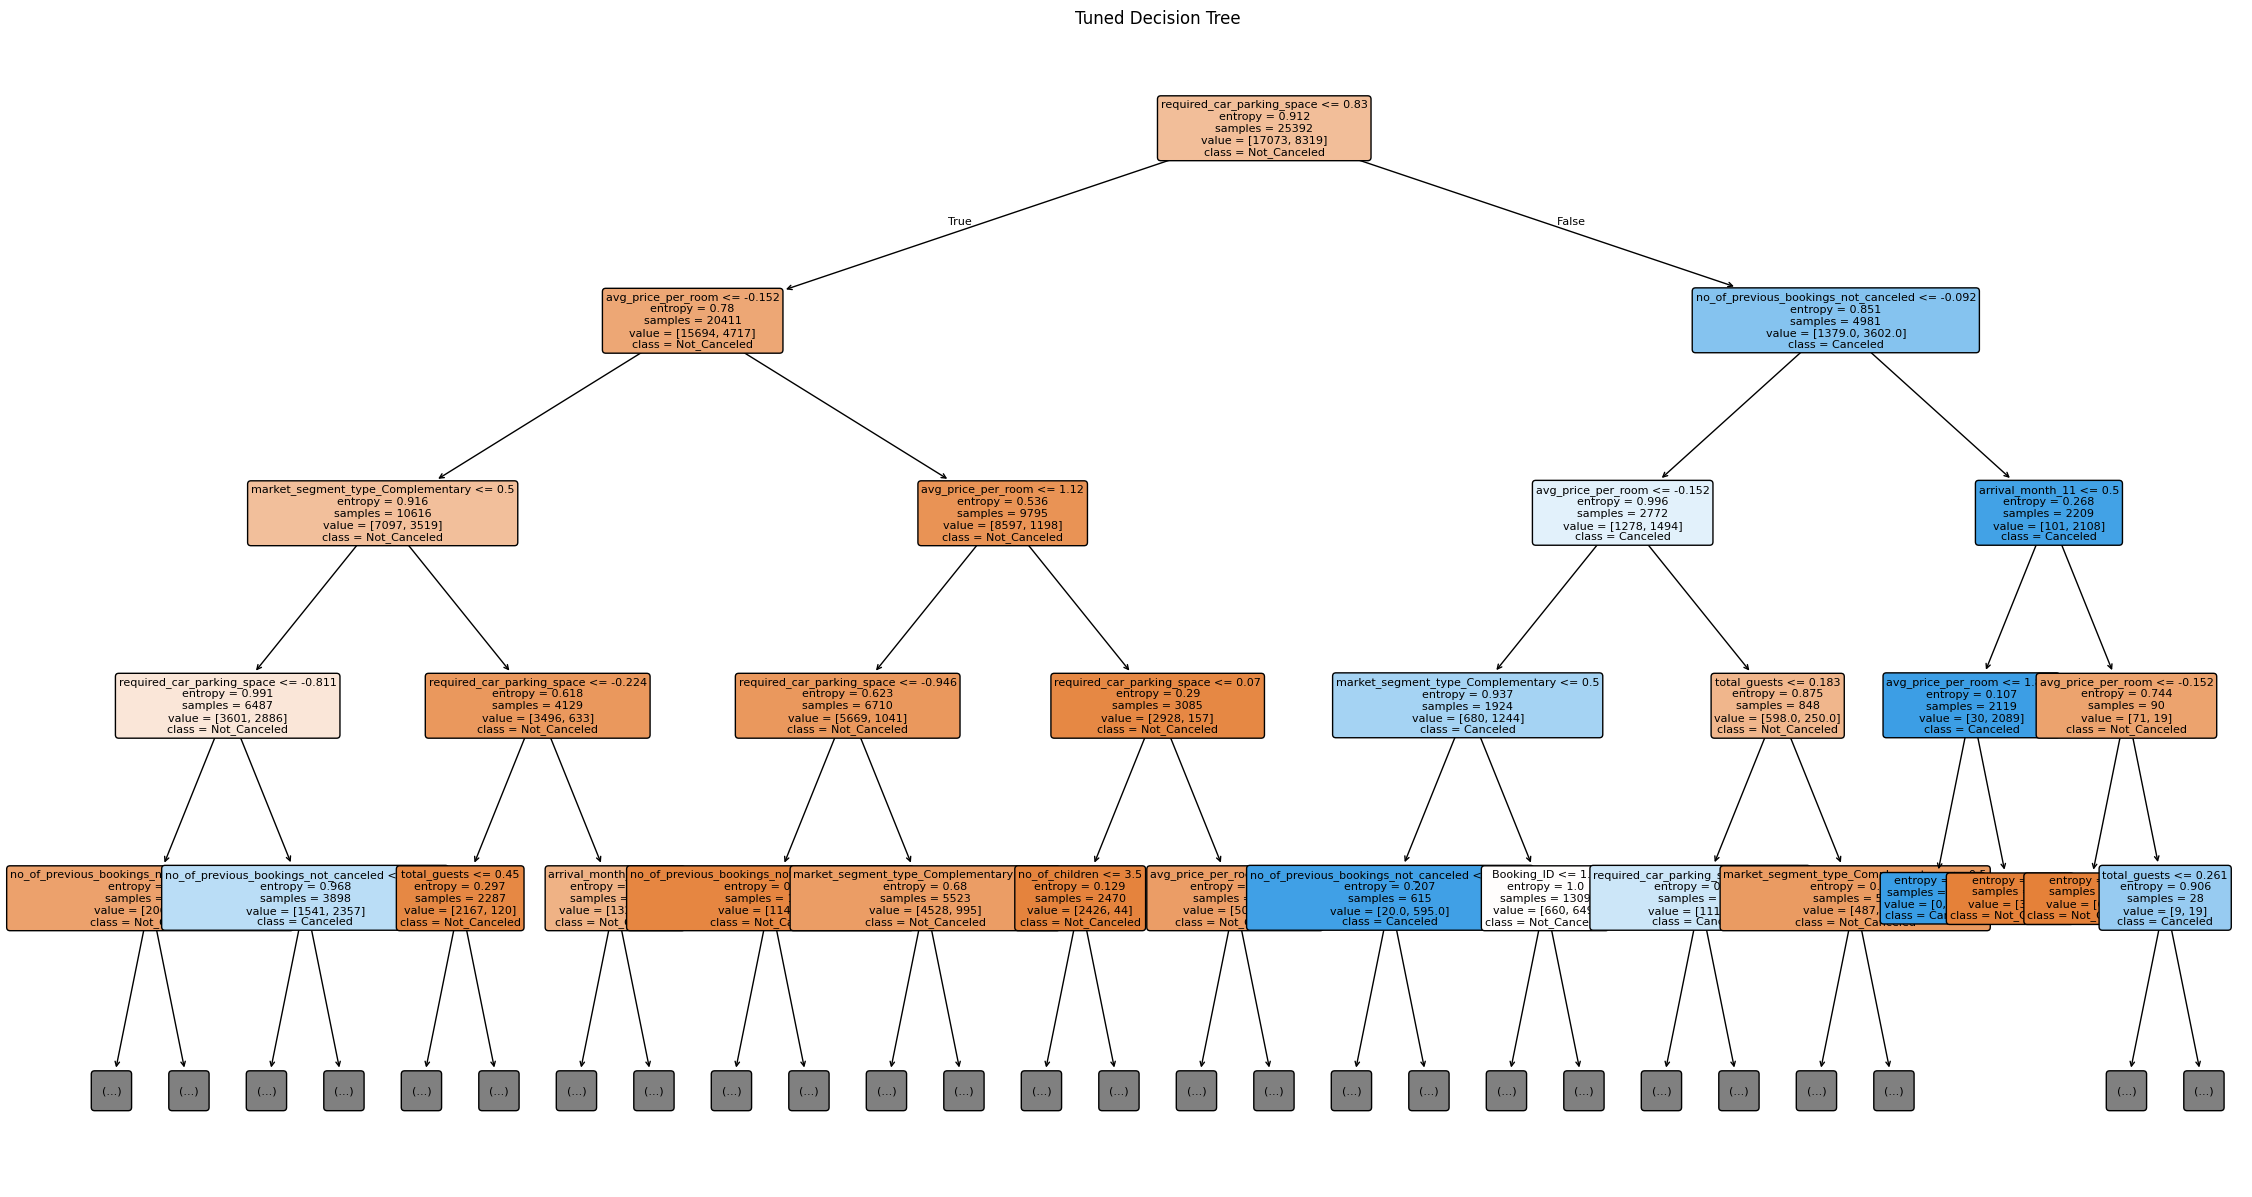

In [201]:
from sklearn.tree import plot_tree

plt.figure(figsize=(28,15))

plot_tree(

    best_tree,

    feature_names=X_train.columns,

    class_names=['Not_Canceled','Canceled'],

    filled=True,

    rounded=True,

    fontsize=8,

    max_depth=4

)

plt.title("Tuned Decision Tree")
plt.show()

### Feature Importance

In [203]:
feature_imp = pd.DataFrame({

'Feature':X_train_tuned.columns,

'Importance':best_tree.feature_importances_

})

feature_imp.sort_values(
    by='Importance',
    ascending=False
).head(10)

,Feature,Importance
4,lead_time,0.414392
9,avg_price_per_room,0.158676
10,no_of_special_requests,0.131964
21,market_segment_type_Offline,0.103025
32,arrival_month_12,0.049405
13,weekend_ratio,0.036728
2,no_of_week_nights,0.024810
0,no_of_adults,0.016148
5,arrival_year,0.015444
3,required_car_parking_space,0.012585


### Tuned Decision Tree Metrics

In [204]:
print(classification_report(
    y_test,
    y_pred_tree
))

              precision    recall  f1-score   support

           0       0.88      0.92      0.90      7317
           1       0.82      0.74      0.78      3566

    accuracy                           0.86     10883
   macro avg       0.85      0.83      0.84     10883
weighted avg       0.86      0.86      0.86     10883

